In [1]:
import numpy as np
import scipy.optimize as sol
import scipy.integrate as integrate
import warnings
import pandas as pd
import pickle
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [2]:
class cell:
    def __init__(self,index,init_clusters,parent,birth,tau):
        '''Initializes cell attributes
        param:: index: cell index
        param:: clusters: count of n-clusters
        param:: x: plasmid trajectory in time 
        param:: t: time stamps for x
        param:: parent: parent cell
        param:: birth: birth time
        return:: None
        '''
        self.index=index
        self.init_clusters=init_clusters
        self.fin_clusters=[]
        self.x = []
        self.t = []
        self.parent = parent
        self.birth = birth
        self.div = birth+tau+np.random.normal(0,1)

#@jit
def find_tot_plasmids(y1,y2,max_size):
    y1[0]+=y1[1]   #because of plasmid shedding y[1] may have a nonzero value, we transfer this to y[0].
    y2[0]+=y2[1]
    y1[1]=y1[0]
    y2[1]=y2[0]
    y_tot1 = np.dot(np.arange(1,max_size),y1[1:max_size])
    y_tot2 = np.dot(np.arange(1,max_size),y2[1:max_size])            
    y_tot = y_tot1+y_tot2
    y1[1]=0
    y2[1]=0
    return y1,y2,y_tot1,y_tot2,y_tot 

#@jit
def pop_check(cells,T):
    b_filter = [x for x in cells if x.t[0] <= T]
    d_filter = [x for x in b_filter if x.t[-1] >T]
    return d_filter #N_pop

#@jit
def hazards(y,c_idx,num_reax,N,beta,gamma,sigma,max_size,t_f): 
    if num_reax>max_size:
        print(num_reax, y)
    a = np.zeros(num_reax)                                     #reaction hazards 
    v = np.zeros([num_reax,max_size])                          #reaction vectors    
    a[0]= 1 #(k_tr*y_totp)/(1+K*y_tot/(s0*6.022e2*n*V))**n     #not needed since computation of reaction time is different 
    v[0,0] = 1
    a[1] = 0.5*beta*y[0]*(y[0]-1)
    v[1,0] = -2
    v[1,2] = 1
    
    if N>1:
        species_idx =np.zeros([2,num_reax])
        count=1
        for i in np.arange(1,N):   #plasmid recruitment
            count+=1
            a[count] = beta*y[0]*y[c_idx[i]]
            species_idx[:,count] = np.array([c_idx[i],0])
        rec_count=count
                
        for i in np.arange(1,N):   #cluster combination
            for j in np.arange(i,N):
                count+=1
                if i==j:
                    a[count] = 0.5*gamma*y[c_idx[i]]*(y[c_idx[j]]-1)
                else:
                    a[count] = gamma*y[c_idx[i]]*y[c_idx[j]]
                species_idx[:,count] = [c_idx[i],c_idx[j]]
        cluster_count = count
            
        for i in np.arange(1,N): #plasmid shedding
            count+=1
            a[count] = sigma*y[c_idx[i]]*c_idx[i]
            species_idx[:,count] = np.array([c_idx[i],0])
                    
        for i in range(len(a)): #reaction vectors
            if i==0:                         #plasmid replication
                v[i,0] = 1
            elif i==1:                       #plasmid duplex formation
                v[i,0] = -2
                v[i,2] = 1
            elif (2<=i and i<=rec_count):    #plasmid recruitment to a cluster
                v[i,0] = -1
                v[i,int(species_idx[0,i])] = -1
                v[i,int(species_idx[0,i])+1] = 1
            elif (i>rec_count and i<=cluster_count):   #cluster combination

                if (int(species_idx[0,i])==int(species_idx[1,i]) and y[int(species_idx[1,i])]>1 ):
                    v[i,int(species_idx[0,i])] = -2
                    v[i,int(np.sum(species_idx[:,i]))] = 1
                elif not(int(species_idx[0,i])==int(species_idx[1,i])):
                    v[i,int(species_idx[0,i])] = -1
                    v[i,int(species_idx[1,i])] = -1
                    v[i,int(np.sum(species_idx[:,i]))] = 1
            else:  #plasmid shedding         
                if int(species_idx[0,i]) == 2:   
                    v[i,0] = 2
                    v[i,int(species_idx[0,i])] = -1 
                else:
                    v[i,0] = 1
                    v[i,int(species_idx[0,i])] = -1
                    v[i,int(species_idx[0,i])-1] = 1 
    return a,v



#@jit
def mnrn(y0,x0,tau,beta,gamma,sigma,max_size):
    y=y0               #plasmid cluster count; y[0]=x[0], y[1]=0, y[i] = number of cluster of size i     
    x=[x0]
    t_x = [0]
    t_y=0              #reaction time 
    y_tot1=x0
    y_tot2 = 0
    y1 = y[:max_size]
    y2 = y[max_size:2*max_size] 
    y_tot=y_tot1+y_tot2
    while t_y<tau:
        print('########## new reaction')
        ############################### pole 1 ##################################    
        if y_tot1>0:
            dummy = y1[0]                                               
            y1[0] = 1
            c_idx1 = np.where(y1>0)[0]                                  #indices of species with non-zero state except possibly free plasmids
            y1[0] = dummy
            print(y1, y_tot1)
            N1 = len(c_idx1)                                            #number of non-zero species
            num_reax1 = N1+1+int(((N1-1)**2-N1+1)/2)+2*(N1-1)           #possible number of reactions given the system state 
            a1,v1 = hazards(y1,c_idx1,num_reax1,N1,beta,gamma,sigma,max_size,t_y)     
        else:
            num_reax1 = 1
            print(y1 , y_tot1)
            a1 = [0]
            v1 = np.zeros([1,max_size])
        
        ############################### pole 2 ##################################
        if y_tot2>0:
            dummy = y2[0]
            y2[0]=1
            c_idx2 = np.where(y2>0)[0]                                  
            y2[0]=dummy
            print(y2, y_tot2)
            N2 = len(c_idx2)
            num_reax2 = N2+1+int(((N2-1)**2-N2+1)/2)+2*(N2-1)  
            a2,v2 = hazards(y2,c_idx2,num_reax2,N2,beta,gamma,sigma,max_size,t_y)
            a = np.append(a1,a2,axis=0)
       
        else:
            num_reax2 = 1
            print(y2, y_tot2)
            a2 = [0]
            a = np.append(a1,a2,axis=0)
            v2 = np.zeros([1,max_size])
            
        a = np.append(a,[rho*y1[0],rho*y2[0]])
        epsilon=np.random.uniform(0,1,len(a))
        t_j  = np.zeros(num_reax1+num_reax2+2)
        
        for i in range(len(a)):
            if a[i]==0:
                t_j[i] = np.inf
            else:
                if i == 0: #replication in pole 1
                    t_j[i] = sol.fsolve(func,0.1,args=(t_y,y_tot1,epsilon[i],y_tot)) 
                elif i == num_reax1:  #replication in pole 2
                    t_j[i] = sol.fsolve(func,0.1,args=(t_y,y_tot2,epsilon[i],y_tot)) 
                else:
                    t_j[i] = -np.log(epsilon[i])/a[i]
        
        j=np.argmin(t_j)
        if (j==num_reax1+num_reax2): #plasmid transfer pole 1 to 2
            y2[0]+=1
            y1[0]-=1
        elif (j==num_reax1+num_reax2+1): #plasmid transfer pole 2 to 1
            y2[0]-=1
            y1[0]+=1
        elif (num_reax1<=j and j<num_reax1+num_reax2):
            y2+=v2[j-num_reax1,:]  
        else:
            y1+=v1[j,:]    
        y1,y2,y_tot1,y_tot2,y_tot = find_tot_plasmids(y1,y2,max_size)
        if (j==0 or j==num_reax1):
            x= np.append(x,y_tot)
            t_x =np.append(t_x,[t_y])
        t_y+=t_j[j]   
    
    y = np.append(y1,y2,axis=0)
    return y,x,t_x

def time_approx(s,xi,y_tot,eps):
    D=k_tr*xi
    C=K*y_tot/(s0*6.022e2*n)
    a_prime = (n*D*C/V0)*np.exp(-mu*s)*(1+(C/V0)*np.exp(-mu*s))**(-n-1)
    a = (k_tr*xi)/(1+K*y_tot/(s0*6.022e2*n*V))**n 
    return (-a+np.sqrt(a^2-2*a_prime*np.log(eps)))/a_prime
    

#@jit
def sim_cells(current,beta,gamma,sigma,max_size):
    y0 = current.init_clusters
    y0[1]=y0[0]
    x0 = np.dot(np.arange(1,max_size),y0[1:max_size])
    y0[1]=0 
    if x0>0:
        yy,xx,tt = mnrn(y0,x0,current.div-current.birth,beta,gamma,sigma,max_size)
    else:
        yy = y0
        xx = np.array([0,0])
        tt = np.array([0,current.div-current.birth])
    return yy,xx,tt


def lineage_sim(c,tau,beta,gamma,sigma,max_size):
    Line=[]
    current_cell = c 
    N=0
    status =1
    free = []
    while status == 1:
        print('############## new cell ##############')
        yy,xx,tt = sim_cells(current_cell,beta,gamma,sigma,max_size)
        #update current cell
        current_cell.fin_clusters = yy
        current_cell.x = xx
        current_cell.t = tt+current_cell.birth  

        free.extend([yy[0]+yy[max_size]])
        Line.extend([current_cell])
        if np.random.uniform(0,1)<0.5:
            daughter = cell(N+1,np.append(yy[:max_size],np.zeros(max_size)),current_cell.index,current_cell.t[-1],tau)
        else:
            daughter = cell(N+1,np.append(yy[max_size:],np.zeros(max_size)),current_cell.index,current_cell.t[-1],tau)
        
        x0 = np.dot(np.arange(1,max_size),daughter.init_clusters[1:max_size])+daughter.init_clusters[0]
        
        if len(Line)%20 == 0:
            print('new')
            print('free cells:',yy[0]+yy[max_size])
            print(len(Line),x0,current_cell.x[-1])
        if current_cell.x[-1]==x0 or x0==0 or len(Line)==5e2:
            status = 0
        else:
            status = 1
            current_cell = daughter
            N+=1
    return Line,free




In [ ]:
##################################################
n =  2.56  #4.84 #2.56 #8.85
s0 = 0.034 #0.06 #0.034 #0.08  
tau = 30             #30-min doubling time
k_tr = 2.17       
K = 15.8/1.26  
mu = np.log(2)/tau
V0 = 1.2
rho = 0.02 #0.15
##################################################

x0=25          #number of plasmids in the initial cell
max_size=200   #total number of possible clusters, can be increased to accomodate larger sims

scale = 1
true_beta = 0.015*scale
true_sigma = 0.08*scale  #0.9 is good small sigma leads to larger asymmetry in inheritance, i.e., wider initial plasmid CN distribution 
true_gamm = 0.05*scale


warnings.filterwarnings('ignore')
repeats = 1
loss = np.zeros(repeats)
for k in range(repeats):
    y0 = np.zeros(2*max_size)
    y0[0]=x0
    c= cell(0,y0,[],0,tau)   #index,clusters,parent,birth
    Line,free = lineage_sim(c,tau,true_beta,true_gamm,true_sigma,max_size)
    loss[k] = 1./len(Line)
    print('Loss prob',1./len(Line))
    
columns=' '
np.savetxt("loss.csv", loss, delimiter=",",header=columns)

In [ ]:
file_name = 'lineage_tau30.pkl'
with open(file_name, 'wb') as file:
    pickle.dump(Line, file)

In [3]:
file_name = './lineage_tau30.pkl'
from pick_cells import cell
with open(file_name, 'rb') as file:
    Line = pickle.load(file)

In [4]:
tau=30
max_size=200

Coefficient of variation:
t =  0 min: CV = 0.3404
t = 15 min: CV = 0.1752
t = 30 min: CV = 0.1076


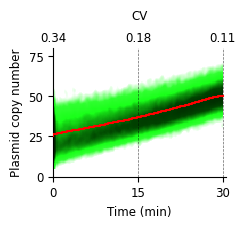

In [16]:
f = plt.figure(figsize=(2.5, 2))
ax = f.add_subplot(111)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
fontsiz = 8.5

gradient_colors = [
    "white",
    "#B8FFB8",
    "#32FF32",
    "#1AFF1A",
    "#004400",
    "#001100"
]

cmap_custom = LinearSegmentedColormap.from_list("dark_green_gradient",gradient_colors,N=256)


t_all = []
x_all = []

for line in Line:

    t_i = line.t - line.birth
    x_i = line.x

    t_all.append(t_i)
    x_all.append(x_i)

t_all = np.concatenate(t_all)
x_all = np.concatenate(x_all)


Nt = 150
Nx = 100

t_bins = np.linspace(t_all.min(),t_all.max(),Nt)
x_bins = np.linspace(x_all.min(),x_all.max(),Nx)
heatmap, t_edges, x_edges = np.histogram2d(t_all,x_all,bins=[t_bins, x_bins],density=True)

sigma_t = 1.2
sigma_x = 1.8

smooth_heatmap = gaussian_filter(heatmap,sigma=(sigma_t, sigma_x))
threshold = 1e-5
masked_heatmap = ma.masked_where(smooth_heatmap < threshold,smooth_heatmap)
                                 
im = ax.imshow(
    masked_heatmap.T,
    origin="lower",
    aspect="auto",
    extent=[
        t_edges[0],
        t_edges[-1],
        x_edges[0],
        x_edges[-1]
    ],
    cmap=cmap_custom,
    interpolation="nearest",
    norm=colors.LogNorm(
        vmin=masked_heatmap.min() + 1e-10,
        vmax=masked_heatmap.max()
    )
)

im.cmap.set_bad(color="white")


# ============================================================
# MEAN TRAJECTORY
# ============================================================

tt = np.linspace(0, tau, samp)

mean_x = np.zeros_like(tt)

for line in Line:
    t = line.t - line.birth
    xx = np.zeros_like(tt)

    for j in range(len(tt)):
        if max(t) >= tt[j]:
            index = np.min(np.where(t >= tt[j])[0])
        else:
            index = len(t) - 1

        xx[j] = line.x[index]
    mean_x += xx

mean_x *= 1.0 / len(Line)
ax.step(tt,mean_x,alpha=1,color='r',zorder=1000)


# ============================================================
# CALCULATE CV AT t = 0, 15, 30 min
# ============================================================

cv_times = np.array([0, 15, 30])
cv_values = []

for t0 in cv_times:
    x_t = []

    for line in Line:
        t = line.t - line.birth
        # Find copy number at the selected time
        if max(t) >= t0:
            index = np.min(
                np.where(t >= t0)[0]
            )

        else:
            index = len(t) - 1
        x_t.append(line.x[index])
    x_t = np.asarray(x_t)

    # Coefficient of variation
    cv = np.std(x_t,ddof=1) / np.mean(x_t)
    cv_values.append(cv)

cv_values = np.asarray(cv_values)
print("Coefficient of variation:")
for t0, cv in zip(cv_times, cv_values):
    print(f"t = {t0:2d} min: CV = {cv:.4f}")


# ============================================================
# AXIS SETTINGS
# ============================================================

ax.set_xlim([0, 30.5])

ax.set_ylim([0, 80])

ax.set_yticks([0, 25, 50, 75])

ax.set_xticks([0, 15, 30])

ax.set_ylabel(
    'Plasmid copy number',
    fontsize=fontsiz
)

ax.set_xlabel(
    'Time (min)',
    fontsize=fontsiz
)

ax.tick_params(
    axis='both',
    which='major',
    labelsize=fontsiz
)


# ============================================================
# FINALIZE
# ============================================================

sns.despine()
plt.tight_layout()

for t0 in cv_times:
    ax.axvline(t0,color='k',linestyle='--',linewidth=0.5,alpha=0.6,zorder=900)

for t0, cv in zip(cv_times, cv_values):
    ax.text(t0,1.03,f'{cv:.2f}',transform=ax.get_xaxis_transform(),ha='center',va='bottom',fontsize=fontsiz)

ax.text(0.5, 1.2, 'CV',transform=ax.transAxes,ha='center',va='bottom',fontsize=fontsiz)
plt.savefig("space_time_density.pdf",format="pdf",bbox_inches="tight")
plt.show()

C:\Users\Jayson Cortez\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Jayson Cortez\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Jayson Cortez\AppData\Local\Temp\ipykernel_16356\1456251430.py:20: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  plt.text(29,6,r'slope = $-$%0.2f' %(-model.coef_),fontsize=fontsiz)


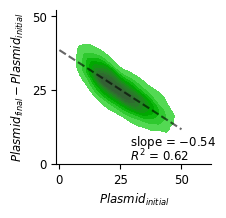

In [23]:
x_vec = np.array(init_x)
y_vec = np.array(fin_x)-np.array(init_x)
model = LinearRegression(fit_intercept=True)
model.fit(x_vec.reshape(-1, 1),y_vec.reshape(-1, 1))
R2=model.score(x_vec.reshape(-1, 1),y_vec.reshape(-1, 1))
t = np.linspace(0,50,100)

f=plt.figure(figsize=(2,2))
ax = f.add_subplot(111)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sns.kdeplot(x=x_vec,y=y_vec,fill='True',color=col[0])
plt.plot(t,model.predict(t.reshape(-1, 1)),color='k',alpha=0.6,zorder=1,linestyle='--')
plt.xticks([0,25,50])
plt.yticks([0,25,50])
plt.xlabel(r'$Plasmid_{initial}$',fontsize=fontsiz)
plt.ylabel(r'$Plasmid_{final}-Plasmid_{initial}$',fontsize=fontsiz)
plt.text(29,6,r'slope = $-$%0.2f' %(-model.coef_),fontsize=fontsiz)
plt.text(29,1,r'$R^2$ = %0.2f' % R2,fontsize=fontsiz)
plt.tick_params(axis="both", labelsize=fontsiz)
sns.despine()
plt.savefig("copy_init_vs_copy_fin.pdf", format="pdf", bbox_inches="tight")

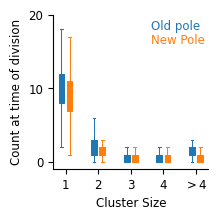

In [5]:
#clust_count1 and 2 are l x m matrices. The columns are cluster sizes
fontsiz=8.5
cluster_count1 = np.zeros([len(Line),max_size])
cluster_count2 = np.zeros([len(Line),max_size])
fin_cluster1 = np.zeros([len(Line),5])

for i in range(max_size):
    cluster_count1[:,i] =  [p.fin_clusters[i] for p in Line]  
    cluster_count2[:,i] =  [p.fin_clusters[i+max_size] for p in Line]

    
f= plt.figure(figsize=(2,2))
ax = f.add_subplot(111)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

def box_plot(data, edge_color, fill_color,pos,out_color):
    bp = ax.boxplot(data, patch_artist=True,positions=pos,showfliers=False,widths=0.35,sym=out_color)
    
    for element in ['boxes', 'whiskers', 'fliers', 'means', 'medians', 'caps']:
        plt.setp(bp[element], color=edge_color, linewidth=0.75)
    for patch in bp['boxes']:
        patch.set(facecolor=fill_color)       
    plt.setp(bp['fliers'], color=edge_color, linewidth=0.25,markersize=1)
    return bp

tags = [1,2,3,4,5]
col1 = 'C0'
col2 = 'C1'
bp11 = box_plot(cluster_count1[:,0], col1, col1,[1], col1)
bp22 = box_plot(cluster_count2[:,0], col2, col2,[1.5],col2)

bp12 = box_plot(cluster_count1[:,tags[1]], col1, col1,[3], col1)
bp22 = box_plot(cluster_count2[:,tags[1]], col2, col2,[3.5],col2)

bp13 = box_plot(cluster_count1[:,tags[2]], col1, col1,[5], col1)
bp23 = box_plot(cluster_count2[:,tags[2]], col2, col2,[5.5],col2)

bp14 = box_plot(cluster_count1[:,tags[3]], col1, col1,[7], col1)
bp24 = box_plot(cluster_count2[:,tags[3]], col2, col2,[7.5],col2)

ccount1=np.zeros_like(Line)
ccount2=np.zeros_like(Line)

for j in range(len(Line)):
    ccount1[j]= np.sum(cluster_count1[j,5:])
    ccount2[j]= np.sum(cluster_count2[j,5:])

bp15 = box_plot(ccount1, col1, col1,[9], col1)
bp25 = box_plot(ccount2, col2, col2,[9.5],col2)


ax.set_xticks([1.25,3.25,5.25,7.25,9.25])
ax.set_xticklabels([1,2,3,4,r'$>4$'],fontsize=fontsiz)
ax.set_xlabel('Cluster Size',fontsize=fontsiz)
ax.set_yticks([0,10,20])
ax.set_ylabel('Count at time of division',fontsize=fontsiz)
ax.text(6.5,18,'Old pole',color=col1,fontsize=fontsiz)
ax.text(6.5,16,'New Pole',color=col2,fontsize=fontsiz)

plt.tick_params(axis="both", labelsize=fontsiz)
sns.despine()
plt.savefig("cluster_sym.pdf", format="pdf", bbox_inches="tight")

In [13]:
import numpy as np

def cohens_d_per_column(A, B):
    A = np.asarray(A)
    B = np.asarray(B)

    n = A.shape[1]
    d_vals = np.zeros(n)
    means_A = np.zeros(n)
    means_B = np.zeros(n)

    for j in range(n):
        a = A[:, j]
        b = B[:, j]

        n1, n2 = len(a), len(b)

        mean1, mean2 = np.mean(a), np.mean(b)
        means_A[j] = mean1
        means_B[j] = mean2

        var1 = np.var(a, ddof=1)
        var2 = np.var(b, ddof=1)

        # Pooled standard deviation
        pooled_sd = np.sqrt(
            ((n1 - 1) * var1 + (n2 - 1) * var2) / (n1 + n2 - 2)
        )

        if pooled_sd == 0:
            d_vals[j] = np.nan
        else:
            d_vals[j] = (mean1 - mean2) / pooled_sd

    return d_vals, means_A, means_B


# Columns corresponding to the first four boxplots
cols = [0, 2, 3, 4]

# Construct matrices corresponding exactly to the five boxplots
A = np.column_stack([
    cluster_count1[:, cols],
    ccount1
])

B = np.column_stack([
    cluster_count2[:, cols],
    ccount2
])

labels = ["1", "2", "3", "4", ">4"]

if __name__ == "__main__":

    d, meanA, meanB = cohens_d_per_column(A, B)

    for label, mA, mB, effect in zip(labels, meanA, meanB, d):
        print(f"Cluster size {label}:")
        print(f"  Mean (Old pole) = {mA:.4f}")
        print(f"  Mean (New pole) = {mB:.4f}")
        print(f"  Cohen's d       = {effect:.3f}\n")

Cluster size 1:
  Mean (Old pole) = 10.4986
  Mean (New pole) = 8.8592
  Cohen's d       = 0.560

Cluster size 2:
  Mean (Old pole) = 1.8170
  Mean (New pole) = 1.6252
  Cohen's d       = 0.155

Cluster size 3:
  Mean (Old pole) = 0.7114
  Mean (New pole) = 0.6154
  Cohen's d       = 0.123

Cluster size 4:
  Mean (Old pole) = 0.4834
  Mean (New pole) = 0.3592
  Cohen's d       = 0.200

Cluster size >4:
  Mean (Old pole) = 1.5638
  Mean (New pole) = 0.5536
  Cohen's d       = 1.410



In [102]:
#single cell dynamics
##################################################
class cell:
    def __init__(self,index,init_clusters,parent,birth,tau):
        '''Initializes cell attributes
        param:: index: cell index
        param:: clusters: count of n-clusters
        param:: x: plasmid trajectory in time 
        param:: t: time stamps for x
        param:: parent: parent cell
        param:: birth: birth time
        return:: None
        '''
        self.index=index
        self.init_clusters=init_clusters
        self.fin_clusters=[]
        self.x = []
        self.t = []
        self.parent = parent
        self.birth = birth
        self.div = birth+tau+np.random.normal(0,1)

def find_tot_plasmids(y1,y2,max_size):
    y1[0]+=y1[1]   #because of plasmid shedding y[1] may have a nonzero value, we transfer this to y[0].
    y2[0]+=y2[1]
    y1[1]=y1[0]
    y2[1]=y2[0]
    y_tot1 = np.dot(np.arange(1,max_size),y1[1:max_size])
    y_tot2 = np.dot(np.arange(1,max_size),y2[1:max_size])            
    y_tot = y_tot1+y_tot2
    y1[1]=0
    y2[1]=0
    return y1,y2,y_tot1,y_tot2,y_tot 

def pop_check(cells,T):
    b_filter = [x for x in cells if x.t[0] <= T]
    d_filter = [x for x in b_filter if x.t[-1] >T]
    return d_filter #N_pop

def hazards(y,c_idx,num_reax,N,beta,gamma,sigma,max_size,t_f,y_totp,y_tot): 
    a = np.zeros(num_reax)                                     #reaction hazards 
    v = np.zeros([num_reax,max_size])                           #reaction vectors    
    #V = V0*np.exp(mu*t_f)
    a[0]= 1 #(k_tr*y_totp)/(1+K*y_tot/(s0*6.022e2*n*V))**n    #not needed since computation of reaction time is different 
    v[0,0] = 1
    a[1] = 0.5*beta*y[0]*(y[0]-1)
    v[1,0] = -2
    v[1,2] = 1
    
    if N>1:
        species_idx =np.zeros([2,num_reax])
        count=1
        for i in np.arange(1,N):   #plasmid recruitment
            count+=1
            a[count] = beta*y[0]*y[c_idx[i]]
            species_idx[:,count] = np.array([c_idx[i],0])
        rec_count=count
                
        for i in np.arange(1,N):   #cluster combination
            for j in np.arange(i,N):
                count+=1
                if i==j:
                    a[count] = 0.5*gamma*y[c_idx[i]]*(y[c_idx[j]]-1)
                else:
                    a[count] = gamma*y[c_idx[i]]*y[c_idx[j]]
                species_idx[:,count] = [c_idx[i],c_idx[j]]
        cluster_count = count
            
        for i in np.arange(1,N): #plasmid shedding
            count+=1
            a[count] = sigma*y[c_idx[i]]*c_idx[i]
            species_idx[:,count] = np.array([c_idx[i],0])
                    
        for i in range(len(a)): #reaction vectors
            if i==0:                         #plasmid replication
                v[i,0] = 1
            elif i==1:                       #plasmid duplex formation
                v[i,0] = -2
                v[i,2] = 1
            elif (2<=i and i<=rec_count):    #plasmid recruitment to a cluster
                v[i,0] = -1
                v[i,int(species_idx[0,i])] = -1
                v[i,int(species_idx[0,i])+1] = 1
            elif (i>rec_count and i<=cluster_count):   #cluster combination
                if (int(species_idx[0,i])==int(species_idx[1,i]) and y[int(species_idx[1,i])]>1 ):
                    v[i,int(species_idx[0,i])] = -2
                    v[i,int(np.sum(species_idx[:,i]))] = 1
                elif not(int(species_idx[0,i])==int(species_idx[1,i])):
                    v[i,int(species_idx[0,i])] = -1
                    v[i,int(species_idx[1,i])] = -1
                    v[i,int(np.sum(species_idx[:,i]))] = 1
            else:  #plasmid shedding         
                if int(species_idx[0,i]) == 2:   
                    v[i,0] = 2
                    v[i,int(species_idx[0,i])] = -1 
                else:
                    v[i,0] = 1
                    v[i,int(species_idx[0,i])] = -1
                    v[i,int(species_idx[0,i])-1] = 1 
    return a,v

def time_approx(s,xi,y_tot,eps):
    D=k_tr*xi
    V=V0*np.exp(mu*s)
    C=K*y_tot/(s0*6.022e2*n)
    a_prime = (mu*n*D*C/V)*(1+C/V)**(-n-1)
    a = D/(1+C/V)**n 
    return (-a+np.sqrt(a**2-2*a_prime*np.log(eps)))/a_prime

def ssa_vol(y0,x0,tau,beta,gamma,sigma,max_size):
    y=y0               #plasmid cluster count; y[0]=x[0], y[1]=0, y[i] = number of cluster of size i     
    x=[x0]
    t_x = [0]
    t_y=0             #reaction time 
    y_tot1=x0
    y_tot2 = 0
    clust = [y]
    ty = []
    y1 = y[:max_size]
    y2 = y[max_size:2*max_size] 
    y_tot=y_tot1+y_tot2
    pole1_x=[x0]
    pole2_x=[0]
    while t_y<tau:
        #print('########## new reaction')
        ############################### pole 1 ##################################    
        if y_tot1>0:
            dummy = y1[0]                                               
            y1[0] = 1
            c_idx1 = np.where(y1>0)[0]                                  #indices of species with non-zero state except possibly free plasmids
            y1[0] = dummy
            N1 = len(c_idx1)                                            #number of non-zero species
            num_reax1 = N1+1+int(((N1-1)**2-N1+1)/2)+2*(N1-1)           #possible number of reactions given the system state 
            a1,v1 = hazards(y1,c_idx1,num_reax1,N1,beta,gamma,sigma,max_size,t_y,y_tot1,y_tot)     
        else:
            num_reax1 = 1
            a1 = [0]
            v1 = np.zeros([1,max_size])
        
        ############################### pole 2 ##################################
        if y_tot2>0:
            dummy = y2[0]
            y2[0]=1
            c_idx2 = np.where(y2>0)[0]                                  
            y2[0]=dummy
            N2 = len(c_idx2)
            num_reax2 = N2+1+int(((N2-1)**2-N2+1)/2)+2*(N2-1)  
            a2,v2 = hazards(y2,c_idx2,num_reax2,N2,beta,gamma,sigma,max_size,t_y,y_tot2,y_tot)
            a = np.append(a1,a2,axis=0)
       
        else:
            num_reax2 = 1
            a2 = [0]
            a = np.append(a1,a2,axis=0)
            v2 = np.zeros([1,max_size])
            
        a = np.append(a,[rho*y1[0],rho*y2[0]])
        epsilon=np.random.uniform(0,1,len(a))
        t_j  = np.zeros(num_reax1+num_reax2+2)
        
        for i in range(len(a)):
            if a[i]==0:
                t_j[i] = np.inf
            else:
                if i == 0: #replication in pole 1
                    t_j[i] = time_approx(t_y,y_tot1,y_tot,epsilon[i])
                elif i == num_reax1:  #replication in pole 2
                    t_j[i] = time_approx(t_y,y_tot2,y_tot,epsilon[i])
                else:
                    t_j[i] = -np.log(epsilon[i])/a[i]
        j=np.argmin(t_j)
        
        if (j==num_reax1+num_reax2): #plasmid transfer pole 1 to 2
            y2[0]+=1
            y1[0]-=1
        elif (j==num_reax1+num_reax2+1): #plasmid transfer pole 2 to 1
            y2[0]-=1
            y1[0]+=1
        elif (num_reax1<=j and j<num_reax1+num_reax2):
            y2+=v2[j-num_reax1,:]  
        else:
            y1+=v1[j,:]    
        y1,y2,y_tot1,y_tot2,y_tot = find_tot_plasmids(y1,y2,max_size)
        if (j==0 or j==num_reax1):
            x= np.append(x,y_tot)
            t_x =np.append(t_x,[t_y])
            pole1_x.append(y_tot1)
            pole2_x.append(y_tot2)
        t_y+=t_j[j]
        ty =np.append(ty,[t_y]) 
        clust = np.vstack((clust,np.append(y1,y2,axis=0)))

    y = np.append(y1,y2,axis=0)
    return y,x,t_x,clust,ty,pole1_x,pole2_x

def sim_cells(current,beta,gamma,sigma,max_size):
    y0 = current.init_clusters
    y0[1]=y0[0]
    x0 = np.dot(np.arange(1,max_size),y0[1:max_size])
    y0[1]=0 
    if x0>0:
        yy,xx,tt,clust,ty,pole1_x,pole2_x = ssa_vol(y0,x0,current.div-current.birth,beta,gamma,sigma,max_size)
    else:
        yy = y0
        xx = np.array([0,0])
        tt = np.array([0,current.div-current.birth])
        clust = np.zeros(max_size)
        ty = np.array([0,current.div-current.birth])
    return yy,xx,tt,clust,ty,pole1_x,pole2_x

def lineage_sim(c,tau,beta,gamma,sigma,max_size):
    Line=[]
    current_cell = c 
    N=0
    length = 1
    status =1
    while status == 1:
        #print('############## new cell ##############')
        yy,xx,tt,clust,ty,pole1_x,pole2_x= sim_cells(current_cell,beta,gamma,sigma,max_size)
        current_cell.fin_clusters = yy
        current_cell.x = xx
        current_cell.t = tt+current_cell.birth  
        
        Line.extend([current_cell])
        if len(Line)>10:
            Line.remove(Line[0]) 
        
        if np.random.uniform(0,1)<0.5:
            daughter = cell(N+1,np.append(yy[:max_size],np.zeros(max_size)),current_cell.index,current_cell.t[-1],tau)
        else:
            daughter = cell(N+1,np.append(yy[max_size:],np.zeros(max_size)),current_cell.index,current_cell.t[-1],tau)
        x0 = np.dot(np.arange(1,max_size),daughter.init_clusters[1:max_size])+daughter.init_clusters[0]
        
        if current_cell.x[-1]==x0 or x0==0 or length==10:
            status = 0
        else:
            length+=1
            
            #print(length)
            status = 1
            current_cell = daughter
            N+=1
    return Line,length,clust,ty,pole1_x,pole2_x

##################################################
n =  2.56  #4.84 #2.56 #8.85
s0 = 0.034 #0.06 #0.034 #0.08  
tau = 30             #30-min doubling time
k_tr = 2.17       
K = 15.8/1.26  
mu = np.log(2)/tau
V0 = 1.2
rho = 0.13

x0=25          #number of plasmids in the initial cell
max_size=200   #total number of possible clusters, can be increased to accomodate larger sims

true_beta = 0.015
true_sigma = 0.08
true_gamm = 0.05

##################################################

warnings.filterwarnings('ignore')
repeats = 1
loss = np.zeros(repeats)
#start_time = time.perf_counter()
for k in range(repeats):
    y0 = np.zeros(2*max_size)
    y0[0]=x0
    c= cell(0,y0,[],0,tau)   #index,clusters,parent,birth
    Line,length,clust,ty,pole1_x,pole2_x = lineage_sim(c,tau,true_beta,true_gamm,true_sigma,max_size)
    loss[k] = 1./length
    #print('Loss prob',1./length)  #return for large rho
print('Loss prob',np.mean(loss),'err',np.std(loss))
#end_time = time.perf_counter()
#elapsed_time = end_time - start_time
#print("Elapsed time: ", elapsed_time)
#np.savetxt("cluster_evolution.csv", clust, delimiter=",",header=" ")
#np.savetxt("cluster_time.csv", ty, delimiter=",",header=" ")
#np.savetxt(str(rho)+".csv", loss, delimiter=",",header=" ")

#file_name = 'last_cells.pkl'
#with open(file_name, 'wb') as file:
#    pickle.dump(Line, file)



Loss prob 0.1 err 0.0


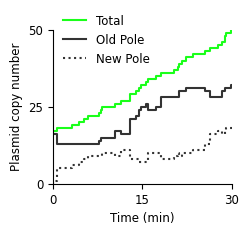

In [203]:
f = plt.figure(figsize=(2.3,2))
ax = f.add_subplot(111)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams.update({'font.size': fontsiz})

ax.step(Line[-1].t-Line[-1].birth,Line[-1].x,color=col[0],label='Total')
ax.step(Line[-1].t-Line[-1].birth,pole1_x,color='k',label='Old Pole',alpha=0.8)
ax.step(Line[-1].t-Line[-1].birth,pole2_x,color='k',linestyle='dotted',label='New Pole',alpha=0.8)
#ax.legend(frameon=False,bbox_to_anchor=(1, 1.1))
ax.legend(ncol=1,frameon=False,bbox_to_anchor=(0.6, 0.7))

ax.set_xlim([0,30])
ax.set_xticks([0,15,30])
ax.set_ylim(0,50)
ax.set_yticks([0,25,50])
ax.set_xlabel('Time (min)')
ax.set_ylabel('Plasmid copy number')
sns.despine()
plt.savefig("single_cell_plasmid.pdf", format="pdf", bbox_inches="tight")